In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c as SPEED_OF_LIGHT_M_S

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "RMFsolver").is_dir() and (candidate / "new_paper_calculations").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the NSM_related project root")

PROJECT_ROOT = find_project_root()
CLUSTER_DIRECTORY = PROJECT_ROOT / "new_paper_calculations" / "26-08-21"
DOMAIN_PATH = CLUSTER_DIRECTORY / "T0plus0p1-domain.npy"
RESULT_PATH = CLUSTER_DIRECTORY / "T0plus0p1-uNmax-angular-wavefront.npy"
LOCAL_OUTPUT_DIRECTORY = PROJECT_ROOT / "local_analysis_results" / "FL26-1"
if str(CLUSTER_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(CLUSTER_DIRECTORY))
import _radial_shell_continuation as radial
import _T0plus0p1_runner as runner

DOMAIN_PAYLOAD = np.load(DOMAIN_PATH, allow_pickle=True).item()
CLUSTER_PAYLOAD = np.load(RESULT_PATH, allow_pickle=True).item()
DOMAIN_POINTS = [dict(point) for point in DOMAIN_PAYLOAD["points"]]
POINTS_BY_GRID_INDEX = {
    (int(point["theta_index"]), int(point["radial_index"])): point
    for point in DOMAIN_POINTS
}
RECORDS_BY_POINT_INDEX = {
    int(record["point_index"]): dict(record)
    for record in CLUSTER_PAYLOAD["radial_shell_records"]
}
PROFILES_BY_POINT_INDEX = {
    int(point_index): dict(profile)
    for point_index, profile in CLUSTER_PAYLOAD["radial_shell_profiles"].items()
}

def point_for(theta_index, radial_index):
    key = (int(theta_index), int(radial_index))
    if key not in POINTS_BY_GRID_INDEX:
        raise KeyError(f"No domain point for theta_index={key[0]}, radial_index={key[1]}")
    point = dict(POINTS_BY_GRID_INDEX[key])
    state = runner._states_for_point(point, (0.1,))[0]
    point.update(state)
    point["nB_0minus_MeV3"] = float(
        point["nB_0minus_over_n0"] * DOMAIN_PAYLOAD["calibration"]["n0_MeV3"]
    )
    return point

def record_for(theta_index, radial_index):
    point = point_for(theta_index, radial_index)
    return dict(RECORDS_BY_POINT_INDEX[int(point["point_index"])])

def profile_for(theta_index, radial_index):
    point = point_for(theta_index, radial_index)
    profile = PROFILES_BY_POINT_INDEX.get(int(point["point_index"]))
    return None if profile is None else dict(profile)

def history_entry(theta_index, radial_index):
    point = point_for(theta_index, radial_index)
    record = record_for(theta_index, radial_index)
    profile = profile_for(theta_index, radial_index)
    if not bool(record.get("success")) or profile is None:
        return None
    return {"point": point, "record": record, "profile": profile}

def successful_theta_indices(radial_index):
    indices = []
    for theta_index in sorted({key[0] for key in POINTS_BY_GRID_INDEX}):
        record = record_for(theta_index, radial_index)
        if bool(record.get("success")) and profile_for(theta_index, radial_index) is not None:
            indices.append(theta_index)
    return tuple(indices)

def failed_theta_indices(radial_index):
    all_indices = sorted({key[0] for key in POINTS_BY_GRID_INDEX})
    successes = set(successful_theta_indices(radial_index))
    return tuple(index for index in all_indices if index not in successes)

RHO_PREVIOUS_RADIAL_INDEX = 16  # rho = 0.84
RHO_TARGET_RADIAL_INDEX = 17    # rho = 0.90
RHO_EARLIER_RADIAL_INDEX = 15   # rho = 0.78
RHO084_SUCCESSFUL_THETA_INDICES = successful_theta_indices(RHO_PREVIOUS_RADIAL_INDEX)
RHO090_SUCCESSFUL_THETA_INDICES = successful_theta_indices(RHO_TARGET_RADIAL_INDEX)
RHO090_FAILED_THETA_INDICES = failed_theta_indices(RHO_TARGET_RADIAL_INDEX)

def _manual_candidates(values, source, *, seed_theta_indices=()):
    candidates = []
    for value in np.atleast_1d(values).astype(float):
        if np.isfinite(value) and value > 0.0:
            candidates.append({
                "jB_guess": float(value),
                "source": str(source),
                "use_profile": True,
                "angular_seed_theta_indices": tuple(int(i) for i in seed_theta_indices),
            })
    if not candidates:
        raise ValueError("No finite positive jB candidate was supplied")
    return tuple(candidates)

def jB_init_choices(
    option,
    custom=None,
    *,
    theta_index,
    theta_success_index=None,
    theta_multipliers=(1.0,),
):
    """Return transparent jB candidates for one rho=0.90 target.

    option='rho_prev' reproduces the cluster's same-theta rho=0.84/0.78 ladder.
    option='theta_success' borrows jB from a successful rho=0.90 theta while
    retaining the target theta's rho=0.84 profile.
    option='custom' uses the scalar or sequence supplied in custom.
    """
    theta_index = int(theta_index)
    target = point_for(theta_index, RHO_TARGET_RADIAL_INDEX)
    previous = history_entry(theta_index, RHO_PREVIOUS_RADIAL_INDEX)
    earlier = history_entry(theta_index, RHO_EARLIER_RADIAL_INDEX)
    if previous is None:
        raise RuntimeError(f"rho=0.84 is not successful for theta_index={theta_index}")
    if option == "rho_prev":
        candidates = radial.primary_candidates(target, previous=previous, earlier=earlier)
        if not candidates:
            raise RuntimeError("The cluster radial candidate ladder returned no candidates")
        return tuple(dict(candidate) for candidate in candidates)
    if option == "theta_success":
        if theta_success_index is None:
            raise ValueError("Set THETA_SUCCESS_INDEX when JB_INIT_OPTION='theta_success'")
        theta_success_index = int(theta_success_index)
        if theta_success_index not in RHO090_SUCCESSFUL_THETA_INDICES:
            raise ValueError(
                f"theta_index={theta_success_index} is not a successful rho=0.90 seed; "
                f"choose from {RHO090_SUCCESSFUL_THETA_INDICES}"
            )
        seed_record = record_for(theta_success_index, RHO_TARGET_RADIAL_INDEX)
        seed_jB = float(seed_record["jB"])
        return _manual_candidates(
            seed_jB * np.asarray(theta_multipliers, dtype=float),
            "manual_rho0p9_theta_success_jB",
            seed_theta_indices=(theta_success_index,),
        )
    if option == "custom":
        if custom is None:
            raise ValueError("Set CUSTOM_JB_CHOICES when JB_INIT_OPTION='custom'")
        return _manual_candidates(custom, "manual_custom_jB")
    raise ValueError("JB_INIT_OPTION must be 'rho_prev', 'theta_success', or 'custom'")

def run_rho09_probe(
    *,
    theta_index,
    jB_option,
    theta_success_index=None,
    custom_jB=None,
    theta_multipliers=(1.0,),
    trial_timeout_s=300.0,
    cell_timeout_s=1200.0,
    tail_eps=1.0e-8,
    n_mesh=200,
    tol_bvp=1.0e-4,
    max_nodes=10000,
    jB_lower_bound=1.0e-12,
    jB_upper_factor=1.0e-4,
    run_solver=False,
    save_result=True,
):
    theta_index = int(theta_index)
    if theta_index not in RHO090_FAILED_THETA_INDICES:
        print(f"Warning: theta_index={theta_index} already has a successful rho=0.90 cluster result")
    point = point_for(theta_index, RHO_TARGET_RADIAL_INDEX)
    previous = history_entry(theta_index, RHO_PREVIOUS_RADIAL_INDEX)
    candidates = jB_init_choices(
        jB_option,
        custom_jB,
        theta_index=theta_index,
        theta_success_index=theta_success_index,
        theta_multipliers=theta_multipliers,
    )
    task = {
        **runner._task_common(DOMAIN_PAYLOAD),
        "point": point,
        "T_0plus_MeV": 0.1,
        "tail_eps": float(tail_eps),
        "n_mesh": int(n_mesh),
        "tol_bvp": float(tol_bvp),
        "max_nodes": int(max_nodes),
        "jB_lower_bound": float(jB_lower_bound),
        "jB_upper_factor": float(jB_upper_factor),
        "trial_timeout_s": float(trial_timeout_s),
        "cell_timeout_s": float(cell_timeout_s),
        "candidates": tuple(candidates),
        "continuation_profile": previous["profile"],
    }
    probe = {
        "status": "preview",
        "theta_index": theta_index,
        "theta_deg": float(point["theta_deg"]),
        "point": point,
        "jB_option": str(jB_option),
        "candidates": tuple(candidates),
        "rho_previous_record": previous["record"],
        "solver_output": None,
        "saved_path": None,
    }
    if run_solver:
        started = time.monotonic()
        solver_output = radial.run_cell_task(task)
        probe["runtime_s"] = float(time.monotonic() - started)
        probe["solver_output"] = solver_output
        selected = solver_output["selected_record"]
        probe["status"] = str(selected.get("status", "failure"))
        if save_result:
            LOCAL_OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
            output_path = LOCAL_OUTPUT_DIRECTORY / f"rho0p9-theta{theta_index:02d}-probe.npy"
            temporary_path = output_path.with_suffix(".tmp.npy")
            probe["saved_path"] = output_path
            np.save(temporary_path, probe, allow_pickle=True)
            temporary_path.replace(output_path)
    return probe

def print_probe_report(probe):
    point = probe["point"]
    print(f"rho=0.84 successful theta indices: {RHO084_SUCCESSFUL_THETA_INDICES}")
    print(f"rho=0.90 successful theta indices: {RHO090_SUCCESSFUL_THETA_INDICES}")
    print(f"rho=0.90 failed theta indices:     {RHO090_FAILED_THETA_INDICES}")
    print("\nSelected target")
    print(f"  theta_index={probe['theta_index']}, theta={probe['theta_deg']:.6g} deg")
    print(f"  rho={point['radial_fraction_used']:.2f}")
    print(f"  T(0-)={point['T_0minus_MeV']:.8g} MeV")
    print(f"  nB(0-)/n0={point['nB_0minus_over_n0']:.8g}")
    print(f"  jB option={probe['jB_option']}")
    print("\nCandidate order")
    for index, candidate in enumerate(probe["candidates"]):
        print(
            f"  {index}: jB={candidate['jB_guess']:.10g}, "
            f"source={candidate['source']}, use_profile={candidate['use_profile']}"
        )
    if probe["solver_output"] is None:
        print("\nPreview only. Set RUN_SOLVER=True to launch the bounded BVP trial.")
        return
    output = probe["solver_output"]
    selected = output["selected_record"]
    print("\nAttempt results")
    for attempt in output["attempt_records"]:
        print(
            f"  attempt={attempt.get('attempt_index')}, status={attempt.get('status')}, "
            f"jB_guess={attempt.get('jB_guess')}, runtime={attempt.get('runtime_s', np.nan):.3g} s, "
            f"source={attempt.get('guess_source')}"
        )
    print("\nSelected result")
    print(f"  status={selected.get('status')}")
    print(f"  message={selected.get('message', '')}")
    if bool(selected.get("success")):
        print(f"  jB={float(selected['jB']):.10g}")
        print(f"  u(0-)={float(selected['u_0minus']) * SPEED_OF_LIGHT_M_S:.8g} m/s")
        print(f"  BVP nodes={selected.get('bvp_nodes')}, iterations={selected.get('bvp_niter')}")
        print(f"  max BVP RMS residual={selected.get('bvp_max_rms_residual')}")
    if probe.get("saved_path") is not None:
        print(f"  saved={probe['saved_path']}")


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Choosing a $\rho=0.90$ target

The imported grid contains 30 angular rays, with `THETA_INDEX` running from `0` to `29` and $\theta$ running uniformly from $0^\circ$ to $90^\circ$.

- At $\rho=0.84$, every index `0-29` has a successful numerical profile. These same-$\theta$ profiles are available as continuation profiles for the target row.
- At $\rho=0.90$, the existing successful indices are `1, 6, 7, 8`, corresponding to $\theta\simeq3.10^\circ,18.62^\circ,21.72^\circ,24.83^\circ$.
- The unresolved indices available for manual probing are `0, 2-5, 9-29`.

Cell 1 recomputes these sets from the loaded payload, so the printed report remains authoritative if the cluster data is replaced. Select one unresolved index with `THETA_INDEX` in the next cell.

## Initial-$j_B$ options and bounded execution

`JB_INIT_OPTION` controls only the shooting guesses. The continuation profile always comes from the target ray's successful $\rho=0.84$ point.

- `"rho_prev"`: reproduce the cluster's same-$\theta$ radial ladder. It extrapolates $j_B$ from $\rho=0.78$ and $0.84$, then tries the cluster's bounded multipliers around the $\rho=0.84$ value.
- `"theta_success"`: take $j_B$ from one successful $\rho=0.90$ ray selected by `THETA_SUCCESS_INDEX`, then apply `THETA_JB_MULTIPLIERS`. The borrowed ray supplies $j_B$ only, not its profile.
- `"custom"`: try `CUSTOM_JB_CHOICES` in the listed order while retaining the target's $\rho=0.84$ profile.

Keep `RUN_SOLVER=False` to inspect the target and candidate order without starting a BVP. Set it to `True` for the actual probe. Each trial is terminated after `TRIAL_TIMEOUT_S`, the entire candidate sequence is bounded by `CELL_TIMEOUT_S`, and a successful or failed manual run can be saved independently under `local_analysis_results/FL26-1/`.

The visualization marks every initial $j_B$ with an open circle. A successful attempt is connected vertically to its converged $j_B$ (diamond); an unsuccessful attempt receives a red cross at its initial value.

In [5]:
# Tunable solver parameters
THETA_INDEX = 0
JB_INIT_OPTION = "rho_prev"  # "rho_prev", "theta_success", or "custom"
THETA_SUCCESS_INDEX = 1           # rho=0.90 successes are printed below
CUSTOM_JB_CHOICES = (120.0, 140.0, 160.0)
THETA_JB_MULTIPLIERS = (1.0, 0.9, 1.1, 0.8, 1.2)
RUN_SOLVER = True                # Change to True only when ready for a bounded BVP run
SAVE_RESULT = False
TRIAL_TIMEOUT_S = 300.0
CELL_TIMEOUT_S = 1200.0
TAIL_EPS = 1.0e-8
N_MESH = 200
TOL_BVP = 1.0e-4
MAX_NODES = 10000
JB_LOWER_BOUND = 1.0e-12
JB_UPPER_FACTOR = 1.0e-4

probe_result = run_rho09_probe(
    theta_index=THETA_INDEX,
    jB_option=JB_INIT_OPTION,
    theta_success_index=THETA_SUCCESS_INDEX,
    custom_jB=CUSTOM_JB_CHOICES,
    theta_multipliers=THETA_JB_MULTIPLIERS,
    trial_timeout_s=TRIAL_TIMEOUT_S,
    cell_timeout_s=CELL_TIMEOUT_S,
    tail_eps=TAIL_EPS,
    n_mesh=N_MESH,
    tol_bvp=TOL_BVP,
    max_nodes=MAX_NODES,
    jB_lower_bound=JB_LOWER_BOUND,
    jB_upper_factor=JB_UPPER_FACTOR,
    run_solver=RUN_SOLVER,
    save_result=SAVE_RESULT,
)
print_probe_report(probe_result)


rho=0.84 successful theta indices: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29)
rho=0.90 successful theta indices: (1, 6, 7, 8)
rho=0.90 failed theta indices:     (0, 2, 3, 4, 5, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29)

Selected target
  theta_index=0, theta=0 deg
  rho=0.90
  T(0-)=0 MeV
  nB(0-)/n0=5.0682082
  jB option=rho_prev

Candidate order
  0: jB=138.2302233, source=adjacent_profile_extrapolated_jB, use_profile=True
  1: jB=102.5579076, source=adjacent_profile_multiplier_jB, use_profile=True
  2: jB=111.4759866, source=adjacent_profile_multiplier_jB, use_profile=True
  3: jB=120.3940655, source=adjacent_profile_multiplier_jB, use_profile=True
  4: jB=133.7711839, source=adjacent_profile_multiplier_jB, use_profile=True

Attempt results
  attempt=0, status=trial_timeout, jB_guess=138.23022333799304, runtime=300 s, source=adjacent_profile_extrapolated_jB
  attempt=1, statu

Saved /Users/janshao/NSM_related/local_analysis_results/FL26-1/rho0p9-theta00-diagnostic.png


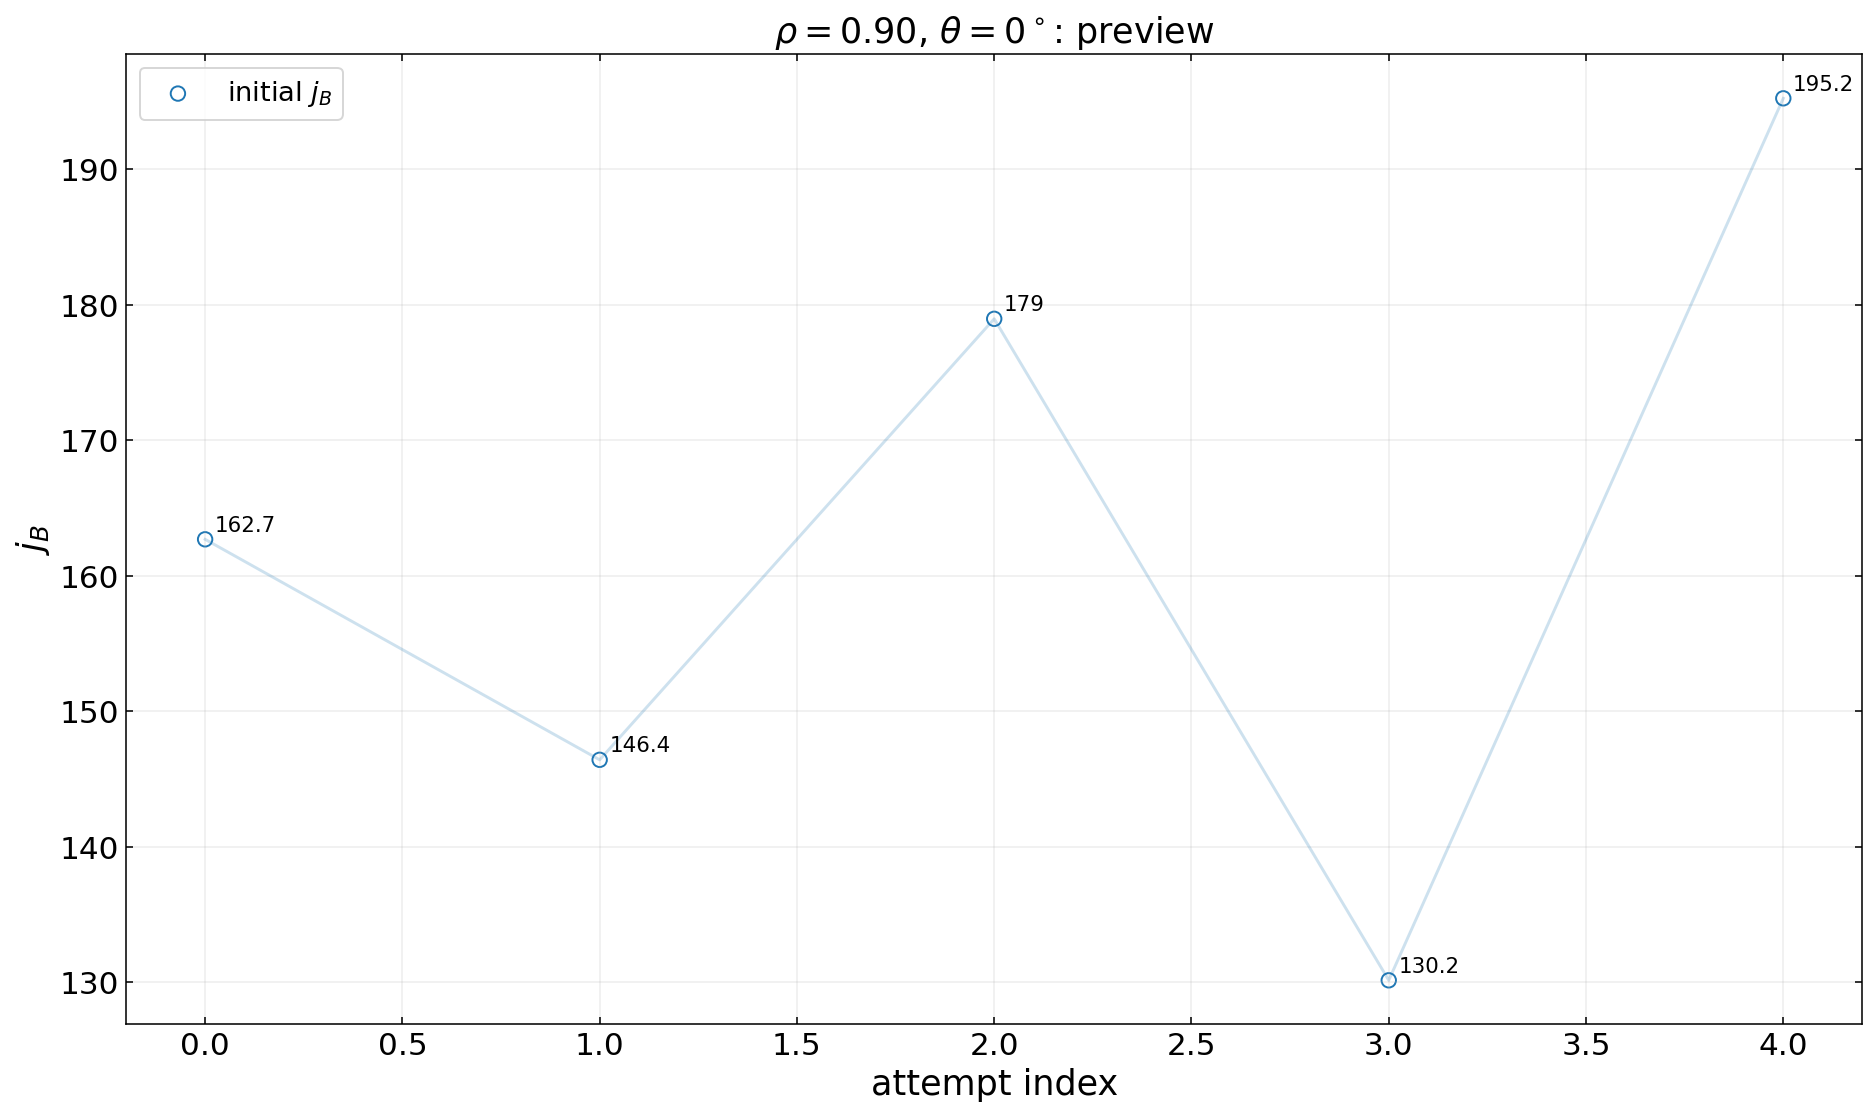

In [3]:
# Tunable plotting parameters
FIGURE_SIZE = (16.0, 9.0)
FIGURE_DPI = 140
EXPORT_DPI = 240
FIGURE_FACE_COLOR = "white"
AXES_FACE_COLOR = "white"
PROFILE_COLOR = "#1f77b4"
TEMPERATURE_COLOR = "#d62728"
VELOCITY_COLOR = "#2ca02c"
CURRENT_COLOR = "#9467bd"
INITIAL_JB_COLOR = "#1f77b4"
CONVERGED_JB_COLOR = "#2ca02c"
FAILED_JB_COLOR = "#d62728"
CONNECTOR_COLOR = "#7f7f7f"
PROFILE_LINE_WIDTH = 2.0
CANDIDATE_LINE_WIDTH = 1.5
CONNECTOR_LINE_WIDTH = 1.5
MARKER_SIZE = 55.0
INITIAL_MARKER = "o"
CONVERGED_MARKER = "D"
FAILED_MARKER = "x"
GRID_ENABLED = True
GRID_ALPHA = 0.22
TITLE_FONT_SIZE = 18
SUPTITLE_FONT_SIZE = 19
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 16
LEGEND_FONT_SIZE = 14
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
PROFILE_X_SCALE = "linear"
PROFILE_X_LIMIT_UM = None
JB_Y_SCALE = "linear"
ANNOTATE_JB_VALUES = True
ANNOTATION_FONT_SIZE = 11
ANNOTATION_X_OFFSET = 5
ANNOTATION_Y_OFFSET = 4
SUBPLOT_HORIZONTAL_SPACE = 0.32
SUBPLOT_VERTICAL_SPACE = 0.36
PROFILE_COLUMN_WIDTHS = (1.0, 1.0, 1.15)
HBAR_C_MEV_FM = 197.3269804
MICROMETERS_PER_FEMTOMETER = 1.0e-9
SAVE_FIGURE = True
OUTPUT_DIRECTORY = PROJECT_ROOT / "local_analysis_results" / "FL26-1"
OUTPUT_PNG = OUTPUT_DIRECTORY / f"rho0p9-theta{probe_result['theta_index']:02d}-diagnostic.png"

def plot_jB_attempt_diagnostics(axis):
    solver_output = probe_result.get("solver_output")
    attempts = [] if solver_output is None else list(solver_output.get("attempt_records", []))
    axis.set_facecolor(AXES_FACE_COLOR)
    if not attempts:
        guesses = np.asarray([candidate["jB_guess"] for candidate in probe_result["candidates"]], dtype=float)
        indices = np.arange(guesses.size)
        axis.plot(indices, guesses, color=INITIAL_JB_COLOR, linewidth=CANDIDATE_LINE_WIDTH, alpha=GRID_ALPHA)
        axis.scatter(indices, guesses, s=MARKER_SIZE, marker=INITIAL_MARKER, facecolors="none", edgecolors=INITIAL_JB_COLOR, label=r"initial $j_B$")
        if ANNOTATE_JB_VALUES:
            for index, value in zip(indices, guesses):
                axis.annotate(f"{value:.4g}", (index, value), xytext=(ANNOTATION_X_OFFSET, ANNOTATION_Y_OFFSET), textcoords="offset points", fontsize=ANNOTATION_FONT_SIZE)
    else:
        for attempt_index, attempt in enumerate(attempts):
            initial_jB = float(attempt.get("jB_guess", np.nan))
            status = str(attempt.get("status", "failure"))
            axis.scatter(attempt_index, initial_jB, s=MARKER_SIZE, marker=INITIAL_MARKER, facecolors="none", edgecolors=INITIAL_JB_COLOR, label=r"initial $j_B$" if attempt_index == 0 else None)
            if status == "success" and np.isfinite(attempt.get("jB", np.nan)):
                converged_jB = float(attempt["jB"])
                axis.plot([attempt_index, attempt_index], [initial_jB, converged_jB], color=CONNECTOR_COLOR, linewidth=CONNECTOR_LINE_WIDTH)
                axis.scatter(attempt_index, converged_jB, s=MARKER_SIZE, marker=CONVERGED_MARKER, color=CONVERGED_JB_COLOR, label=r"converged $j_B$" if "converged" not in axis.get_legend_handles_labels()[1] else None)
                if ANNOTATE_JB_VALUES:
                    axis.annotate(f"{converged_jB:.4g}", (attempt_index, converged_jB), xytext=(ANNOTATION_X_OFFSET, ANNOTATION_Y_OFFSET), textcoords="offset points", fontsize=ANNOTATION_FONT_SIZE, color=CONVERGED_JB_COLOR)
            else:
                axis.scatter(attempt_index, initial_jB, s=MARKER_SIZE, marker=FAILED_MARKER, color=FAILED_JB_COLOR, label="failed attempt" if "failed attempt" not in axis.get_legend_handles_labels()[1] else None)
    axis.set_yscale(JB_Y_SCALE)
    axis.set_xlabel("attempt index", fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(r"$j_B$", fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(r"shooting path: initial $j_B\rightarrow$ converged $j_B$", fontsize=TITLE_FONT_SIZE)
    axis.grid(GRID_ENABLED, alpha=GRID_ALPHA)
    axis.tick_params(labelsize=TICK_LABEL_FONT_SIZE, direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT)
    axis.legend(fontsize=LEGEND_FONT_SIZE)

solver_output = probe_result.get("solver_output")
profile = None if solver_output is None else solver_output.get("profile")
if profile is not None:
    fig = plt.figure(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, facecolor=FIGURE_FACE_COLOR)
    grid = fig.add_gridspec(2, 3, width_ratios=PROFILE_COLUMN_WIDTHS, wspace=SUBPLOT_HORIZONTAL_SPACE, hspace=SUBPLOT_VERTICAL_SPACE)
    profile_axes = (
        fig.add_subplot(grid[0, 0]),
        fig.add_subplot(grid[0, 1]),
        fig.add_subplot(grid[1, 0]),
        fig.add_subplot(grid[1, 1]),
    )
    jB_axis = fig.add_subplot(grid[:, 2])
    x_um = np.asarray(profile["x"], dtype=float) * HBAR_C_MEV_FM * MICROMETERS_PER_FEMTOMETER
    plotted = (
        (profile_axes[0], np.asarray(profile["a"], dtype=float), PROFILE_COLOR, r"$a=n_K/n_B$"),
        (profile_axes[1], np.asarray(profile["T_profile"], dtype=float), TEMPERATURE_COLOR, r"$T$ [MeV]"),
        (profile_axes[2], np.asarray(profile["u"], dtype=float) * SPEED_OF_LIGHT_M_S, VELOCITY_COLOR, r"$u$ [m s$^{-1}$]"),
        (profile_axes[3], np.asarray(profile["jK"], dtype=float), CURRENT_COLOR, r"$j_K$"),
    )
    for axis, values, color, ylabel in plotted:
        axis.set_facecolor(AXES_FACE_COLOR)
        axis.plot(x_um, values, color=color, linewidth=PROFILE_LINE_WIDTH)
        axis.set_xscale(PROFILE_X_SCALE)
        if PROFILE_X_LIMIT_UM is not None:
            axis.set_xlim(PROFILE_X_LIMIT_UM)
        axis.set_xlabel(r"$x$ [$\mu$m]", fontsize=AXIS_LABEL_FONT_SIZE)
        axis.set_ylabel(ylabel, fontsize=AXIS_LABEL_FONT_SIZE)
        axis.grid(GRID_ENABLED, alpha=GRID_ALPHA)
        axis.tick_params(labelsize=TICK_LABEL_FONT_SIZE, direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT)
    plot_jB_attempt_diagnostics(jB_axis)
    fig.suptitle(rf"$\rho=0.90$, $\theta={probe_result['theta_deg']:.3g}^\circ$: successful numerical profile", fontsize=SUPTITLE_FONT_SIZE)
else:
    fig, jB_axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, facecolor=FIGURE_FACE_COLOR)
    plot_jB_attempt_diagnostics(jB_axis)
    jB_axis.set_title(rf"$\rho=0.90$, $\theta={probe_result['theta_deg']:.3g}^\circ$: {probe_result['status']}", fontsize=TITLE_FONT_SIZE)
if SAVE_FIGURE:
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_PNG, dpi=EXPORT_DPI, facecolor=FIGURE_FACE_COLOR, bbox_inches="tight")
    print(f"Saved {OUTPUT_PNG}")
plt.show()
